<a href="https://colab.research.google.com/github/JoshEliell/ColabFiles/blob/main/Ejercicios_sobre_Clases_No_Balanceadas%2C_Data_Leakage_(Pipeline)_y_SVM_274705.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Ejercicios sobre Clases No Balanceadas, Data Leakage (Pipeline) y SVM
---


## Datos del Estudiante

*   Apellidos y Nombre: Victor Joshua Hernandez Ramom
*   Matrícula: 274705

---


In [8]:
# Carga de Bibliotecas y Conjunto de Datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
from sklearn.pipeline import Pipeline # Para el baseline
from imblearn.pipeline import Pipeline as ImbPipeline # Pipeline de imblearn para data leakage
from imblearn.combine import SMOTEENN
from imblearn.under_sampling import OneSidedSelection

# Semilla para reproducibilidad
SEED = 42

from google.colab import drive
drive.mount('/content/drive')

# Cargar el conjunto de datos
info_path = '/content/drive/MyDrive/ClassFiles/compustat.csv'
df = pd.read_csv(info_path)

# Separar variables predictoras (X) y etiqueta (y), ignorando 'idx'
X = df.drop(columns=['idx', 'label'])
y = df['label']

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


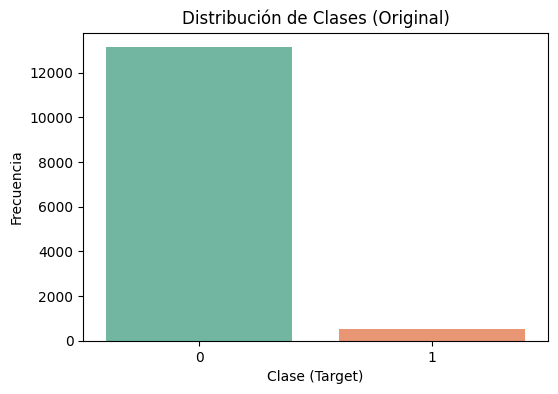

Distribución original:\nlabel
0    13137
1      520
Name: count, dtype: int64
Porcentaje de la clase 1 (minoritaria): 3.81%


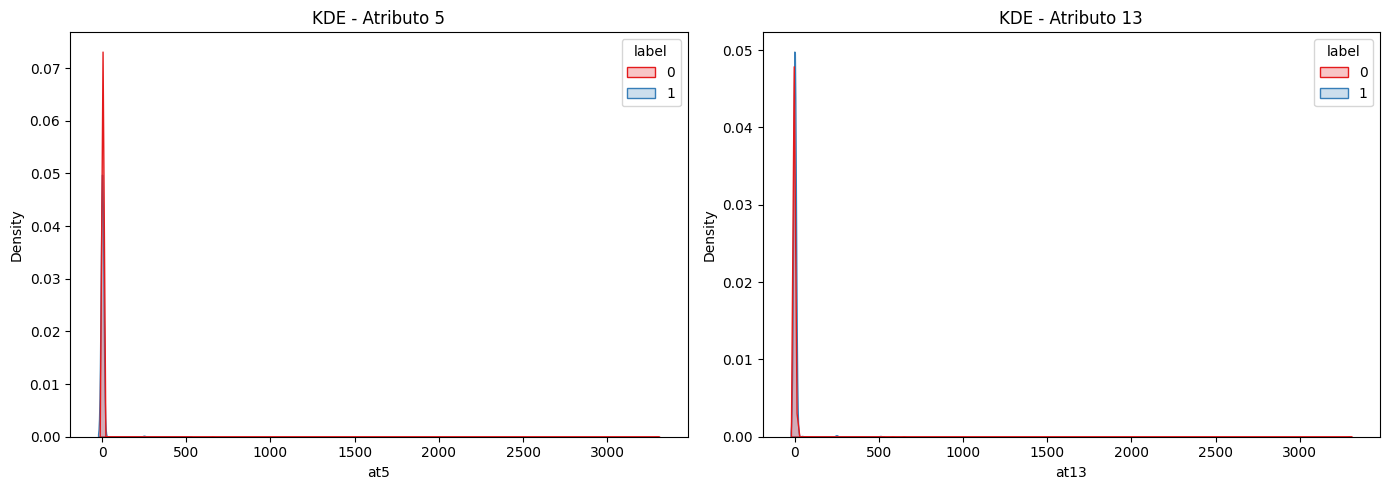

In [9]:
# 1 Analisis Exploratorio de Datos (AED)
# Diagrama de barras de la distribución de clases
plt.figure(figsize=(6, 4))
sns.countplot(x=y, hue=y, palette="Set2", legend=False)
plt.title("Distribución de Clases (Original)")
plt.xlabel("Clase (Target)")
plt.ylabel("Frecuencia")
plt.show()

# Conteo exacto
print(f"Distribución original:\\n{y.value_counts()}")
print(f"Porcentaje de la clase 1 (minoritaria): {(y.value_counts()[1]/len(y))*100:.2f}%")

# Diagramas de densidad KDE para atributos 5 y 13
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(data=df, x='at5', hue='label', common_norm=False, fill=True, ax=axes[0], palette="Set1")
axes[0].set_title("KDE - Atributo 5")

sns.kdeplot(data=df, x='at13', hue='label', common_norm=False, fill=True, ax=axes[1], palette="Set1")
axes[1].set_title("KDE - Atributo 13")

plt.tight_layout()
plt.show()

El grafico de barras y los conteos confirman un desbalance extremo en los datos. La clase 0 (mayoritaria) representa aproximadamente el 96.2% de los datos, mientras que la clase 1 (minoritaria) representa solo el 3.8% (520 casos frente a 13137). Los graficos de densidad (KDE) para los atributos 5 y 13 muestran colas largas (outliers extremos) y un gran solapamiento entre las clases, esto indica que para el modelo sera difícil distinguir la clase minoritaria sin aplicar tecnicas de balanceo.

In [10]:
# 2. Modelo Base (Baseline)
# Creacion del Pipeline Base (sin balanceo)
pipeline_base = Pipeline([
    ('scaler', StandardScaler()),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=SEED))
])

# Configuracion de Validacion cruzada estratificada
cv_stratified = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ['accuracy', 'precision', 'recall', 'f1']

# Evaluación del Baseline
scores_base = cross_validate(pipeline_base, X, y, cv=cv_stratified, scoring=scoring)

# Predicciones para Matriz de Confusión
y_pred_base = cross_val_predict(pipeline_base, X, y, cv=cv_stratified)

resultados = []
resultados.append({
    'Modelo': 'Baseline (Sin Balanceo)',
    'Accuracy': np.mean(scores_base['test_accuracy']),
    'Precision': np.mean(scores_base['test_precision']),
    'Recall': np.mean(scores_base['test_recall']),
    'F1-Score': np.mean(scores_base['test_f1'])
})

print("Resultados del Modelo Base:")
pd.DataFrame(resultados)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Resultados del Modelo Base:


,Modelo,Accuracy,Precision,Recall,F1-Score
0,Baseline (Sin Balanceo),0.962217,0.6,0.007692,0.015166


Implementación utilizando ImbPipeline para evitar el "Data Leakage" garantizando que las transformaciones (StandardScaler y el sobre/submuestreo) solo se apliquen a las particiones de entrenamiento de cada fold, protegiendo los datos de prueba.

In [11]:
# 3 y 4. Tratamiento de clases no Balanceadas y entrenamiento
# SMOTEENN (Sobremuestreo + Limpieza con ENN)
# Aplicamos fit_resample al dataset original para observar como altera las clases
smoteenn = SMOTEENN(random_state=SEED)
X_res_smenn, y_res_smenn = smoteenn.fit_resample(X, y)
print(f"Distribución teórica tras SMOTEENN:\\n{pd.Series(y_res_smenn).value_counts()}\\n")

# One-Sided Selection (Submuestreo)
oss = OneSidedSelection(random_state=SEED)
X_res_oss, y_res_oss = oss.fit_resample(X, y)
print(f"Distribución teórica tras One-Sided Selection:\\n{pd.Series(y_res_oss).value_counts()}\\n")

# Pipeline SMOTEENN (Entrenamiento correcto)
pipeline_smoteenn = ImbPipeline([
    ('scaler', StandardScaler()),
    ('smoteenn', SMOTEENN(random_state=SEED)),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=SEED))
])

# Pipeline One-Sided Selection (Entrenamiento correcto)
pipeline_oss = ImbPipeline([
    ('scaler', StandardScaler()),
    ('oss', OneSidedSelection(random_state=SEED)),
    ('svm', SVC(kernel='rbf', C=1.0, gamma='scale', random_state=SEED))
])

# Evaluaciones
scores_smoteenn = cross_validate(pipeline_smoteenn, X, y, cv=cv_stratified, scoring=scoring)
y_pred_smoteenn = cross_val_predict(pipeline_smoteenn, X, y, cv=cv_stratified)

scores_oss = cross_validate(pipeline_oss, X, y, cv=cv_stratified, scoring=scoring)
y_pred_oss = cross_val_predict(pipeline_oss, X, y, cv=cv_stratified)

# Guardar resultados
resultados.append({
    'Modelo': 'SMOTEENN',
    'Accuracy': np.mean(scores_smoteenn['test_accuracy']),
    'Precision': np.mean(scores_smoteenn['test_precision']),
    'Recall': np.mean(scores_smoteenn['test_recall']),
    'F1-Score': np.mean(scores_smoteenn['test_f1'])
})

resultados.append({
    'Modelo': 'One-Sided Selection (OSS)',
    'Accuracy': np.mean(scores_oss['test_accuracy']),
    'Precision': np.mean(scores_oss['test_precision']),
    'Recall': np.mean(scores_oss['test_recall']),
    'F1-Score': np.mean(scores_oss['test_f1'])
})

Distribución teórica tras SMOTEENN:\nlabel
1    13080
0    11888
Name: count, dtype: int64\n
Distribución teórica tras One-Sided Selection:\nlabel
0    12994
1      520
Name: count, dtype: int64\n


,Modelo,Accuracy,Precision,Recall,F1-Score
0,Baseline (Sin Balanceo),0.962217,0.600000,0.007692,0.015166
1,SMOTEENN,0.811159,0.143910,0.800000,0.243934
2,One-Sided Selection (OSS),0.962217,0.833333,0.011538,0.022679


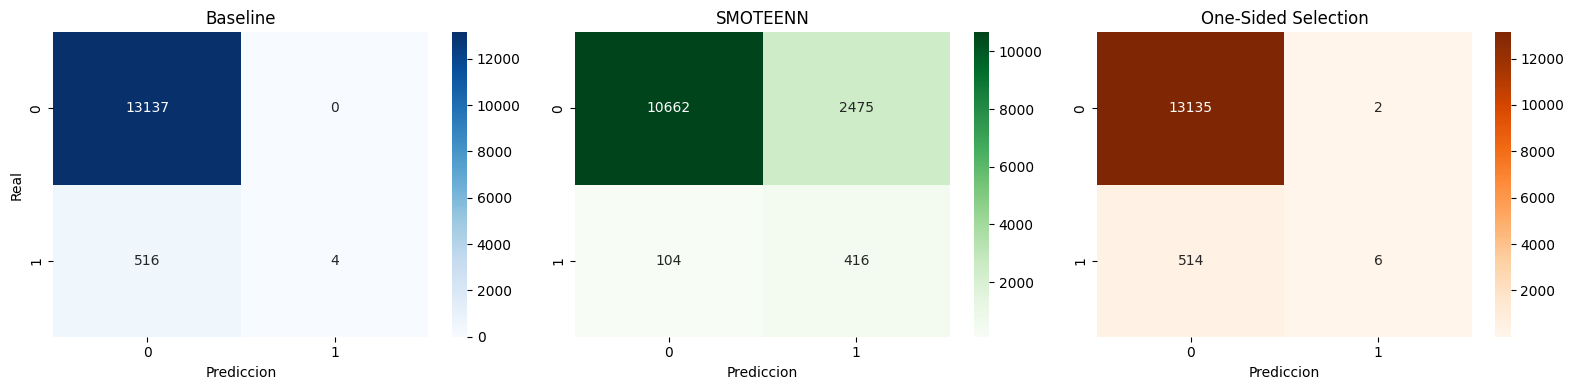

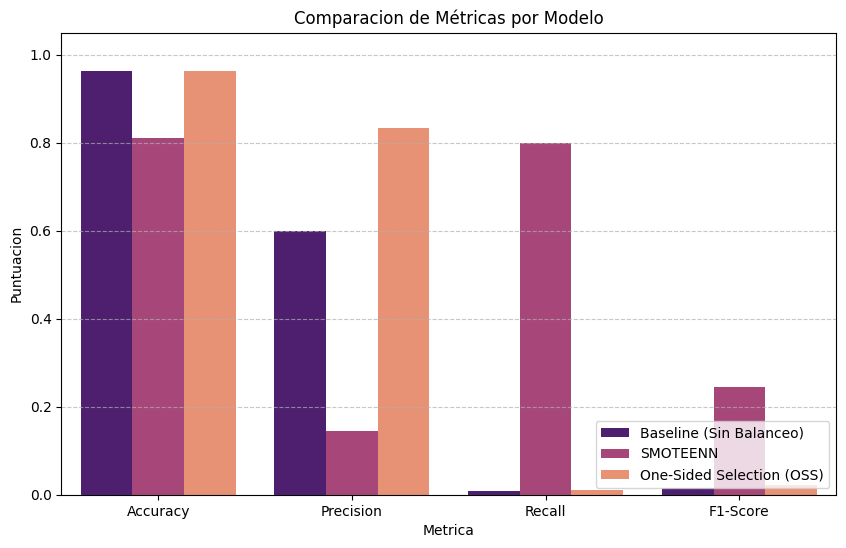

In [12]:
# 5. Evaluación de Resultados
# Mostrar tabla comparativa de métricas
df_resultados = pd.DataFrame(resultados)
display(df_resultados)

# Generar Matrices de Confusión
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.heatmap(confusion_matrix(y, y_pred_base), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Baseline')
axes[0].set_xlabel('Prediccion')
axes[0].set_ylabel('Real')

sns.heatmap(confusion_matrix(y, y_pred_smoteenn), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('SMOTEENN')
axes[1].set_xlabel('Prediccion')

sns.heatmap(confusion_matrix(y, y_pred_oss), annot=True, fmt='d', cmap='Oranges', ax=axes[2])
axes[2].set_title('One-Sided Selection')
axes[2].set_xlabel('Prediccion')

plt.tight_layout()
plt.show()

# Gráfica comparativa de métricas
df_resultados_melted = df_resultados.melt(id_vars="Modelo", var_name="Metrica", value_name="Puntuacion")
plt.figure(figsize=(10, 6))
sns.barplot(x="Metrica", y="Puntuacion", hue="Modelo", data=df_resultados_melted, palette="magma")
plt.title("Comparacion de Métricas por Modelo")
plt.ylim(0, 1.05)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## 6. Discusión y Conclusiones Tecnicas

1. El impacto del desbalance sobre el desempeño del modelo y sobre la metrica de Accuracy:
Como se observo en el modelo Baseline, el desbalance masivo (~96% contra ~4%) provoca que la metrica de Accuracy sea totalmente engañosa. El modelo base logro más del 96% de Accuracy simplemente prediciendo "Clase 0" en casi todos los casos. Al revisar la matriz de confusión y el *Recall* (cercano a 0), es evidente que el modelo ignoro casi por completo a la clase 1. Esto demuestra que en problemas desbalanceados (como fraude o riesgo financiero), el Accuracy no es suficiente. Uno debe centrarse en el F1-Score y el Recall de la clase minoritaria.

2. Diferencias observadas entre SMOTEENN y One-Sided Selection:

*   SMOTEENN: Es una tecnica combinada (hibrida). Primero hace *Oversampling* sintetico de la clase minoritaria usando SMOTE y luego hace *Undersampling* limpiando las fronteras ruidosas con ENN (Edited Nearest Neighbors). Esto ayuda a balancear las clases (casi 50/50) y mejora la capacidad del modelo de encontrar la clase 1 (incrementando el *Recall*), aunque esto suele sacrificar algo de Precision al generar mas Falsos Positivos.
*   One-Sided Selection (OSS): Es una tecnica puramente de Undersampling. Intenta eliminar los ejemplos ruidosos o de la frontera de la clase mayoritaria usando los Enlaces de Tomek y la regla de 1-NN. Debido a que la clase 0 era gigantesca (mas de 13 mil datos), OSS elimina datos pero sigue dejando un fuerte desbalance, por lo que su comportamiento y sus metricas tienden a ser muy similares a las del Baseline original.

3. ¿Qué método produjo los mejores resultados y por qué?
Para este tipo de problema donde el objetivo principal suele ser detectar la clase minoritaria (clase 1), SMOTEENN es el mejor metodo. Aunque la exactitud global (Accuracy) disminuya un poco debido a los falsos positivos que introduce en la clase 0, su capacidad para elevar el Recall y mejorar el F1-Score demuestra que el modelo logra aprender las fronteras de decisión de la clase minoritaria gracias a la generación de datos sinteticos y la limpieza de ruido de la clase dominante. OSS se queda corto porque el simple submuestreo no es suficiente para compensar un desbalance original tan extremo de 96 a 4.